<a href="https://colab.research.google.com/github/MLILA05/COU07506-labs/blob/main/COU07506_Week02_240242422800.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Week 2 — Lab 1: Setting Up the DSP Laboratory

- Name: DAUDI MUSA MLILA
- Registration number: 240242422800
- Date:24/11/2026
- Group: 7

## Pre-lab question
### 1\. Aliasing

A 7 kHz tone sampled at 10 kHz appears at 3 kHz. The Nyquist frequency is kHz. The 7 kHz tone folds back to kHz.

### 2\. Quantization and SQNR

An 8-bit quantizer has levels. For a range of ±1 V, the step size is V, or 7.8125 mV. The theoretical SQNR for a full-scale sine wave is dB.

## Week 2 — Lab 1A: Sampling, Aliasing and Quantization

## Task 2.1 — Aliasing of a sinusoid

Sampling rate (Hz)   Nyquist (Hz)   Observed (Hz)
                10              5               3
                12              6               5
                14              7               7
                20             10               7


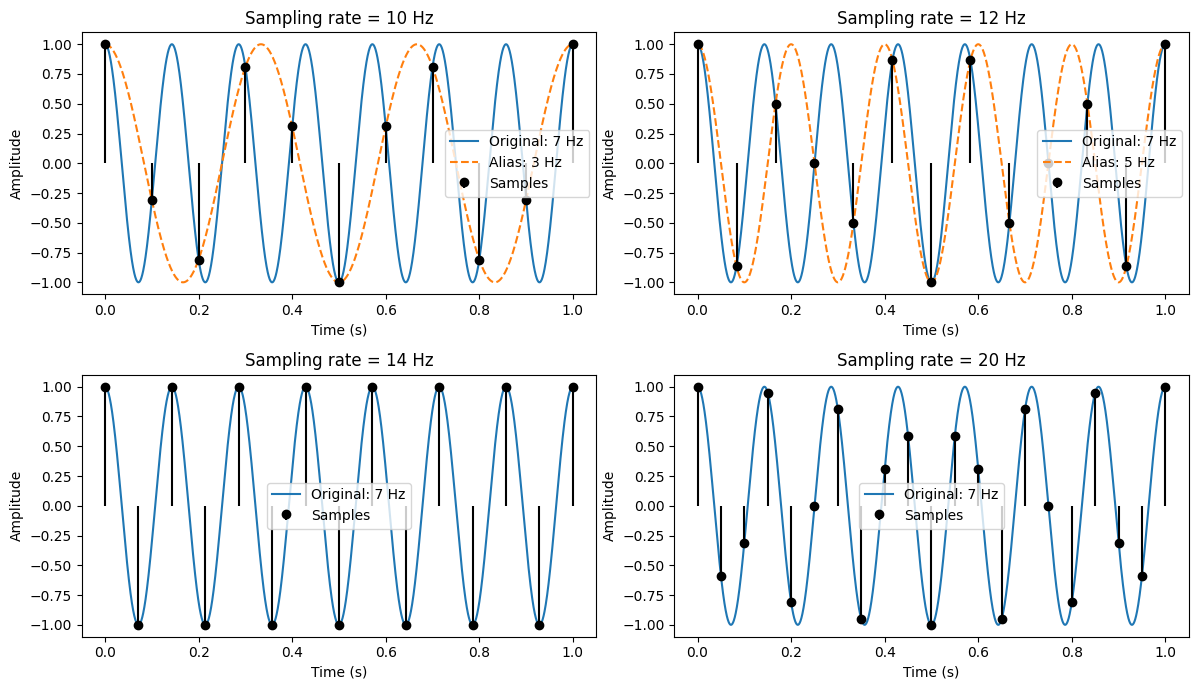

In [11]:
import numpy as np
import matplotlib.pyplot as plt

f0 = 7
sampling_rates = [10, 12, 14, 20]
t = np.linspace(0, 1, 2000)

fig, axes = plt.subplots(2, 2, figsize=(12, 7))

print(f"{'Sampling rate (Hz)':>18} {'Nyquist (Hz)':>14} {'Observed (Hz)':>15}")

for ax, fs in zip(axes.flat, sampling_rates):
    tn = np.arange(fs + 1) / fs
    f_alias = abs(f0 - fs * round(f0 / fs))

    samples = np.cos(2 * np.pi * f0 * tn)
    alias_samples = np.cos(2 * np.pi * f_alias * tn)
    assert np.allclose(samples, alias_samples)

    ax.plot(t, np.cos(2 * np.pi * f0 * t), label="Original: 7 Hz")
    if f_alias != f0:
        ax.plot(
            t, np.cos(2 * np.pi * f_alias * t),
            "--", label=f"Alias: {f_alias} Hz"
        )
    ax.stem(tn, samples, linefmt="k-", markerfmt="ko",
            basefmt=" ", label="Samples")
    ax.set_title(f"Sampling rate = {fs} Hz")
    ax.set_xlabel("Time (s)")
    ax.set_ylabel("Amplitude")
    ax.legend()

    print(f"{fs:>18} {fs / 2:>14g} {f_alias:>15g}")

plt.tight_layout()
plt.show()

## Task 2.2 — Hear aliasing

In [12]:
from pathlib import Path

import numpy as np
from IPython.display import Audio, display
from scipy import signal
from scipy.io import wavfile

audio_path = Path("/content/my_voice.wav")
if not audio_path.is_file():
    audio_path = Path("/my_voice.wav")

if audio_path.is_file():
    fs, recording = wavfile.read(audio_path)
    x = recording.astype(float)

    if recording.dtype == np.uint8:
        x -= 128
    if x.ndim == 2:
        x = x.mean(axis=1)

    x = x[:4 * fs]  # Use the same four seconds as in Week 1
    print("Source: Week 1 voice recording")
else:
    fs = 44_100
    t = np.arange(3 * fs) / fs
    x = 0.5 * signal.chirp(t, f0=200, t1=3, f1=15_000)
    print("Source: fallback chirp (200 Hz to 15 kHz)")

for k in [2, 4, 8]:
    new_fs = round(fs / k)
    naive = x[::k]
    filtered = signal.decimate(x, k, ftype="fir")

    # Give both clips the same playback gain for a fair comparison.
    peak = max(np.max(np.abs(naive)), np.max(np.abs(filtered)), 1e-12)

    print(f"\nk = {k} | New sampling rate: {new_fs:,} Hz")
    print("Without a filter")
    display(Audio(naive / peak, rate=new_fs, normalize=False))
    print("With an anti-aliasing filter")
    display(Audio(filtered / peak, rate=new_fs, normalize=False))

Source: Week 1 voice recording

k = 2 | New sampling rate: 24,000 Hz
Without a filter


With an anti-aliasing filter



k = 4 | New sampling rate: 12,000 Hz
Without a filter


With an anti-aliasing filter



k = 8 | New sampling rate: 6,000 Hz
Without a filter


With an anti-aliasing filter


## Task 2.3 — A uniform quantizer

Step size = 0.25 V
Levels used (V): [-1.   -0.75 -0.5  -0.25  0.    0.25  0.5   0.75]


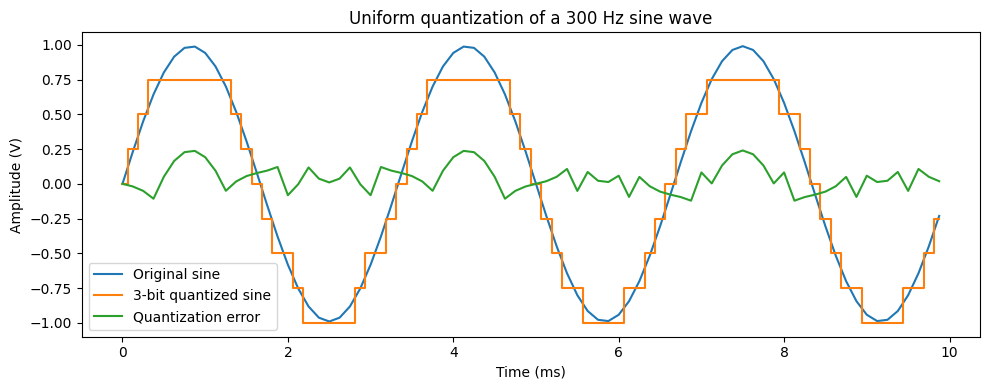

In [13]:
import numpy as np
import matplotlib.pyplot as plt

def quantize(samples, bits, full_scale=1.0):
    delta = 2 * full_scale / 2**bits
    rounded = np.round(samples / delta) * delta
    return np.clip(rounded, -full_scale, full_scale - delta)

fs_sine = 8_000
t_sine = np.arange(80) / fs_sine  # 80 samples in 10 ms
sine = 0.99 * np.sin(2 * np.pi * 300 * t_sine)

sine_quantized = quantize(sine, bits=3)
quantization_error = sine - sine_quantized

print("Step size = 0.25 V")
print("Levels used (V):", np.unique(sine_quantized))

plt.figure(figsize=(10, 4))
plt.plot(t_sine * 1_000, sine, label="Original sine")
plt.step(t_sine * 1_000, sine_quantized, where="mid", label="3-bit quantized sine")
plt.plot(t_sine * 1_000, quantization_error, label="Quantization error")
plt.title("Uniform quantization of a 300 Hz sine wave")
plt.xlabel("Time (ms)")
plt.ylabel("Amplitude (V)")
plt.legend()
plt.tight_layout()
plt.show()

## Task 2.4 — Verify the 6 dB-per-bit rule

Bits   Measured (dB)   Theory (dB)
   2            9.60         13.80
   4           23.58         25.84
   6           36.81         37.88
   8           48.93         49.92
  10           62.81         61.96
  12           72.84         74.00
  14           88.13         86.04
  16           98.91         98.08


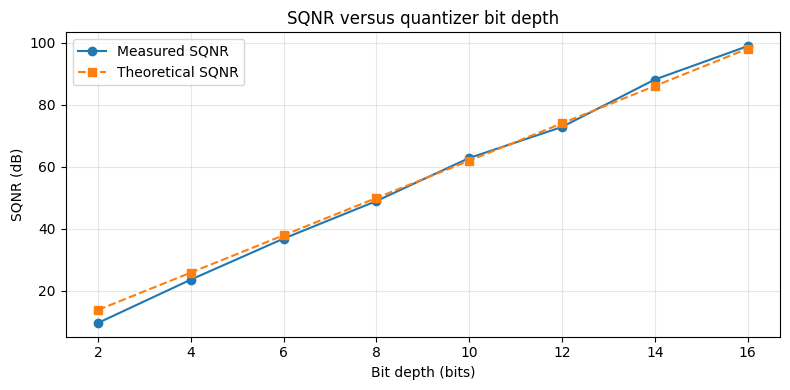

In [14]:
bit_depths = np.arange(2, 17, 2)
signal_energy = np.sum(sine**2)
measured_sqnr = []

for bits in bit_depths:
    quantized = quantize(sine, bits)
    error = sine - quantized
    error_energy = np.sum(error**2)
    sqnr = 10 * np.log10(signal_energy / error_energy)
    measured_sqnr.append(sqnr)

theoretical_sqnr = 6.02 * bit_depths + 1.76

print(f"{'Bits':>4} {'Measured (dB)':>15} {'Theory (dB)':>13}")
for bits, measured, theory in zip(bit_depths, measured_sqnr, theoretical_sqnr):
    print(f"{bits:>4} {measured:>15.2f} {theory:>13.2f}")

plt.figure(figsize=(8, 4))
plt.plot(bit_depths, measured_sqnr, "o-", label="Measured SQNR")
plt.plot(bit_depths, theoretical_sqnr, "s--", label="Theoretical SQNR")
plt.title("SQNR versus quantizer bit depth")
plt.xlabel("Bit depth (bits)")
plt.ylabel("SQNR (dB)")
plt.xticks(bit_depths)
plt.grid(alpha=0.3)
plt.legend()
plt.tight_layout()
plt.show()

## Task 2.5 — Quantize your voice

In [15]:
# Scale the recording so its largest absolute amplitude is 1.
voice = x / np.max(np.abs(x))

# Use the quantize() function from Task 2.3.
voice_4bit = quantize(voice, bits=4)

print("Original voice")
display(Audio(voice, rate=fs, normalize=False))

print("4-bit voice")
display(Audio(voice_4bit, rate=fs, normalize=False))
error_4bit = voice - voice_4bit

signal_energy = np.sum(voice**2)
error_energy = np.sum(error_4bit**2)

sqnr_4bit = 10 * np.log10(signal_energy / error_energy)
print(f"4-bit voice SQNR = {sqnr_4bit:.2f} dB")
for bits in [8, 12]:
    quantized_voice = quantize(voice, bits=bits)
    error = voice - quantized_voice
    error_energy = np.sum(error**2)
    sqnr = 10 * np.log10(signal_energy / error_energy)

    print(f"{bits}-bit voice SQNR = {sqnr:.2f} dB")
    display(Audio(quantized_voice, rate=fs, normalize=False))


Original voice


4-bit voice


4-bit voice SQNR = 14.12 dB
8-bit voice SQNR = 37.94 dB


12-bit voice SQNR = 61.94 dB


### Week 2 — Analysis Questions

### 1\. Why does the 7 Hz tone appear at 3 Hz?

At a sampling rate of 10 Hz, the Nyquist frequency is Hz. The 7 Hz tone is 2 Hz above that limit, so it folds to 3 Hz below the limit.

f_{\\text{alias}} = |7-10| = 3\\text{ Hz}

For  frequency-axis sketch, draw a horizontal axis from 0 to 10 Hz. Mark 3 Hz as the alias, 5 Hz as the Nyquist frequency, and 7 Hz as the original tone. Draw a curved arrow from 7 Hz to 3 Hz over the 5 Hz mark. In Task 2.1, the black sample markers lie on both cosine curves because the two tones give the same values at the sampling instants.

### 2\. Why can’t the aliasing be removed afterwards?

When samples are dropped without filtering, some high-frequency components fold into the same frequency range as genuine low-frequency components. After they overlap, a filter cannot tell which part came from which frequency. Removing the aliased component would also remove any genuine signal at that frequency. This is why the low-pass filter is applied before dropping samples.

### 3\. How much does SQNR change when one bit is added?

The theoretical SQNR increases by 6.02 dB per bit for a full-scale sine wave. My measured sine-wave SQNR increased from 48.93 dB at 8 bits to 62.81 dB at 10 bits. That gives:

\\frac{62.81-48.93}{10-8}=6.94\\text{ dB per bit}

The measurement approximately agrees with the rule. My voice results were even closer. From 8 to 12 bits, the SQNR increased from 37.94 dB to 61.94 dB, which is 6.00 dB per bit.

### 4\. What sampling rate and bit depth should the temperature sensor use?

I would use 10 samples per second (10 Hz) and a 14-bit quantizer.

* Sampling rate. At 10 Hz, samples are 0.1 seconds apart. Since the temperature changes by at most , it can change by at most between samples.

* Bit depth. A 14-bit quantizer gives levels. Over the 0–100 °C range, the step size is , which meets the required 0.01 °C resolution. With 13 bits, the step would be about 0.0122 °C, so 14 bits is the minimum.
*